# Project 01 · Exotic Trading Book Management — Barrier & Rainbow Options


> **Reproducibility:** All values are simulated or assumed; these are educational pricing and risk-management demonstrations, not production trade recommendations. Re-run the cells from top to bottom.

> **How to run:** Open from the repository root (or `notebooks/`); the first code cell configures the engine import path. Install packages with `pip install -r requirements.txt`.


In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'engines').exists():
    root = root.parent
assert (root / 'engines').exists(), 'Launch Jupyter from the repository root or notebooks folder'
sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize':(10,4.5),'axes.grid':True})


## Trading mandate and product conventions

**Source:** `SPOILER_Commo_projects.html`, **Project 3: Exotic Trading Book Management for Barrier and Rainbow Options** (Exotic Trader). Simulate a commodity exotica book on crude oil, gold and copper over **21 days**, with a **2× volatility shock on day 10**, delta hedging, gradual unwind, and P&L reporting.

**From the brief:** initial oil **$78/bbl**, gold **$2,650/oz**, copper **$4/lb**; volatility **25% / 15% / 20%**; common pairwise correlation **0.50**.

**Explicit implementation choices (not specified in the brief):** oil **up-and-out call** with strike **$78** and barrier **$100**, one year to expiry, **1,000 bbl per option contract**; short **20** barrier contracts and short **4** best-of notes. Each rainbow note pays **$100,000 × max(0, max(terminal percentage return of oil, gold, copper))**. A rainbow payoff is based on *returns*, avoiding comparison of different underlying price units. Risk-neutral drift is **2%**. Daily Greek-neutral underlying hedges, an oil vanilla-call proxy hedge for parallel vega, and a five-day unwind after volatility exceeds **30%**. All numbers are synthetic.

**Methods:** lognormal correlated paths generated by Cholesky; antithetic Monte Carlo; Brownian-bridge adjustment to oil barrier survival; pathwise rainbow payoff; common-random-number finite differences; daily mark-to-market hedging. We do not model dividends, futures curves, slippage, credit or actual market liquidity.

In [2]:
from engines.models import barrier_mc, rainbow_mc, rainbow_greeks, shocks, simulate_book
spots = np.array([78.,2650.,4.]); vols=np.array([.25,.15,.20]); rho=.50
n_paths=2000
z=shocks(n_paths,63,3,seed=117)
barrier_mark=barrier_mc(78,78,100,.02,1.,.25,z=z[:,:,:1])
rainbow_mark=rainbow_mc(spots,vols,rho,.02,1.,z=z,reference=spots,payoff_notional=100000)
print('Barrier price per barrel:',round(barrier_mark['price'],4),'95% CI:',(round(barrier_mark['ci_low'],4),round(barrier_mark['ci_high'],4)))
print('Rainbow premium per $100K payoff note:',round(rainbow_mark['price'],2),'95% CI:',(round(rainbow_mark['ci_low'],2),round(rainbow_mark['ci_high'],2)))

Barrier price per barrel: 1.2979 95% CI: (1.1545, 1.4413)
Rainbow premium per $100K payoff note: 16945.81 95% CI: (16110.1, 17781.52)


## Model and Greeks

For correlated risk-neutral geometric Brownian motions:

\[dS_i/S_i = r\,dt + \sigma_i\,dW_i,\quad \mathrm{Corr}(dW_i,dW_j)=\rho_{ij}.\]

A best-of rainbow call has payoff \(N\max(0,\max_i(S_{i,T}/S_{i,0}-1))\). Our barrier payoff is \(\max(S_T-K,0)\mathbf 1_{\{\max S_t<B\}}\).

Delta is estimated as \(\partial V/\partial S_i\) using spot bumps with the same Gaussian paths. Parallel vega measures sensitivity to a simultaneous 1.00 (100-vol-point) change in all asset volatilities (rescale by 0.01 for a 1-vol-point interpretation). The short book combines both exotic liabilities; underlying hedge positions are offsetting the sum of their deltas. Daily mark-to-market excludes any realized bid/ask spread beyond our explicit turnover cost. A single oil vanilla call neutralizes the modeled scalar *parallel* vega, but leaves independent gold/copper volatility factors unhedged.

In [3]:
g=rainbow_greeks(spots,vols,rho,.02,1.,z,reference=spots)
print('Rainbow deltas ($ premium / $ spot):',np.round(g['delta'],3))
print('Rainbow parallel vega ($ premium / 100 vol pts):',round(g['vega_parallel'],2))
print('Rainbow individual spot gammas:',np.round(g['gamma'],3))
print('Rainbow cross-gamma matrix ($ / $spot_i / $spot_j):')
print(np.round(g['cross_gamma'],4))

Rainbow deltas ($ premium / $ spot): [ 480.904    8.234 7476.361]
Rainbow parallel vega ($ premium / 100 vol pts): 75991.44
Rainbow individual spot gammas: [3.0421000e+01 2.8000000e-02 1.2670981e+04]
Rainbow cross-gamma matrix ($ / $spot_i / $spot_j):
[[ 3.04209000e+01 -2.72500000e-01 -2.15828200e+02]
 [-2.72500000e-01  2.80000000e-02 -5.98610000e+00]
 [-2.15828200e+02 -5.98610000e+00  1.26709809e+04]]


## Run the 21-day hedge and 2× volatility spike

The underlying positions are calculated from exotic portfolio delta plus the delta from the oil vanilla **vega-proxy hedge** at the *current* mark. We book the day's P&L from **yesterday's positions**, then change hedges and exotic size at today's price, charging turnover costs. This prevents look-ahead bias. Unwinding reduces short exposure by 20% each day from day 10 through day 14.

**Limitations:** oil barrier events are checked only at four intraday observations along the realized path. Pricing assumes continuously monitored barriers using Brownian bridges. Because of this approximation the realized knock-out and pricing conventions are not identical.

,day,oil,gold,copper,oil_vol,barrier_contracts,rainbow_contracts,daily_pnl,cumulative_pnl
0,0,78.000,2650.000,4.000,0.25,-20.0,-4.0,-26.649,-26.649
1,1,79.361,2671.304,4.010,0.25,-20.0,-4.0,298.013,271.364
2,2,78.275,2655.584,3.983,0.25,-20.0,-4.0,-377.786,-106.421
3,3,79.003,2652.833,4.047,0.25,-20.0,-4.0,250.421,143.999
4,4,80.331,2646.539,4.035,0.25,-20.0,-4.0,-825.074,-681.075
5,5,77.623,2575.331,3.898,0.25,-20.0,-4.0,-1769.622,-2450.697
6,6,77.832,2569.811,3.901,0.25,-20.0,-4.0,-55.546,-2506.243
7,7,77.693,2571.989,3.923,0.25,-20.0,-4.0,-26.107,-2532.350
8,8,76.655,2545.779,3.937,0.25,-20.0,-4.0,12.005,-2520.345
9,9,77.914,2540.035,3.887,0.25,-20.0,-4.0,168.477,-2351.868


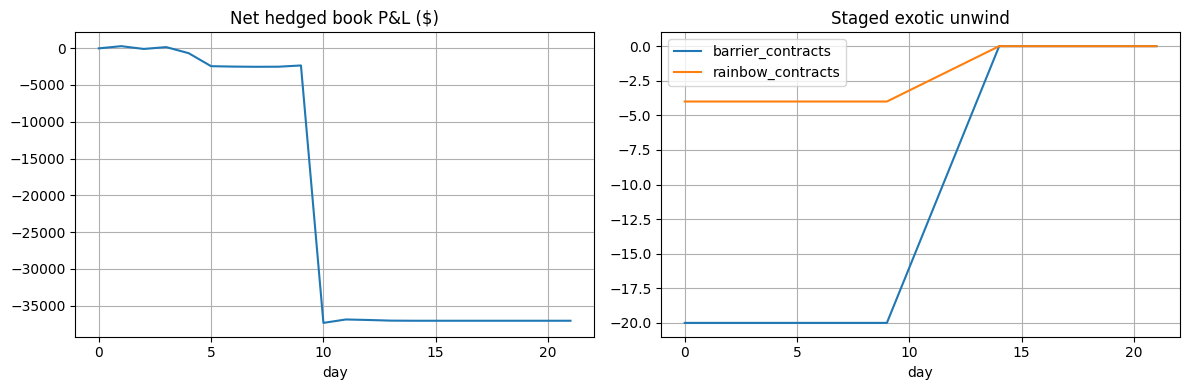

In [4]:
book=simulate_book(n=1200,seed=17,spike_day=10,vol_multiplier=2.,barrier=100.)
display(book[['day','oil','gold','copper','oil_vol','barrier_contracts','rainbow_contracts','daily_pnl','cumulative_pnl']].round(3))
fig,axs=plt.subplots(1,2,figsize=(12,4))
book.plot(x='day',y='cumulative_pnl',ax=axs[0],title='Net hedged book P&L ($)',legend=False)
book.plot(x='day',y=['barrier_contracts','rainbow_contracts'],ax=axs[1],title='Staged exotic unwind')
plt.tight_layout();plt.show()

## Volatility, Greeks, and hedge diagnostics

The volatility shock moves *all* commodities simultaneously; the implementation uses post-shock volatilities for pricing and realized path generation. Actual realized hedging performance can remain volatile around the upper barrier due to delta jumps and discrete rebalancing.

Oil vanilla hedge positions (first/last): 1896.09 -0.0


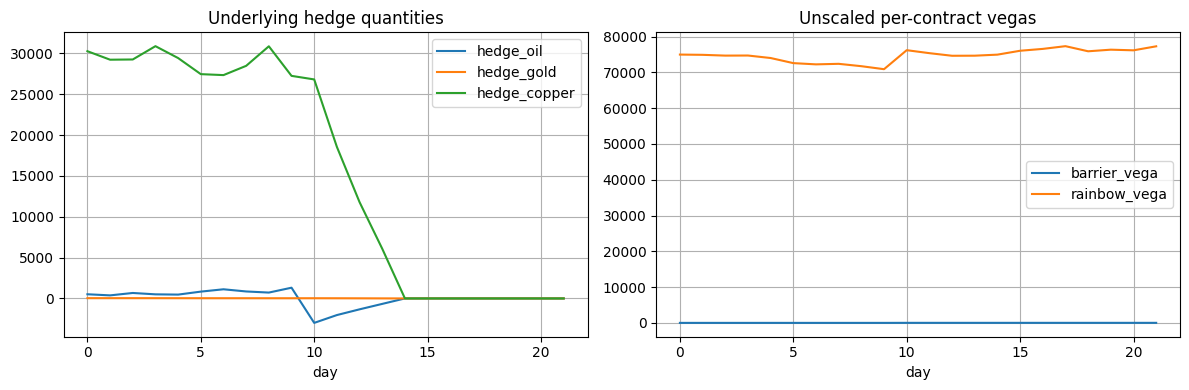

Final P&L: -37055.93
Total execution costs: 167.29
Daily net P&L st.dev: 7627.88
Unwound fraction: 100.0 %


In [5]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
book.plot(x='day',y=['hedge_oil','hedge_gold','hedge_copper'],ax=axs[0],title='Underlying hedge quantities')
book.plot(x='day',y=['barrier_vega','rainbow_vega'],ax=axs[1],title='Unscaled per-contract vegas')
print('Oil vanilla hedge positions (first/last):',round(book.vanilla_hedge.iloc[0],2),round(book.vanilla_hedge.iloc[-1],2))
plt.tight_layout();plt.show()
print('Final P&L:',round(book.cumulative_pnl.iloc[-1],2))
print('Total execution costs:',round(book.transaction_cost.sum(),2))
print('Daily net P&L st.dev:',round(book.daily_pnl.iloc[1:].std(),2))
print('Unwound fraction:',round(book.unwound_pct.iloc[-1]*100,1),'%')

## Correlation sensitivity and final desk commentary

For a best-of **return** call, pairwise correlation changes the distribution of the maximum. Repeat pricing with **common random numbers** to isolate the correlation effect. The scenarios below are illustrations, not forecasts.

,correlation,rainbow_price,stderr
0,0.00,20055.30,410.13
1,0.25,18538.48,421.71
2,0.50,16945.81,426.38
3,0.75,14943.83,420.10


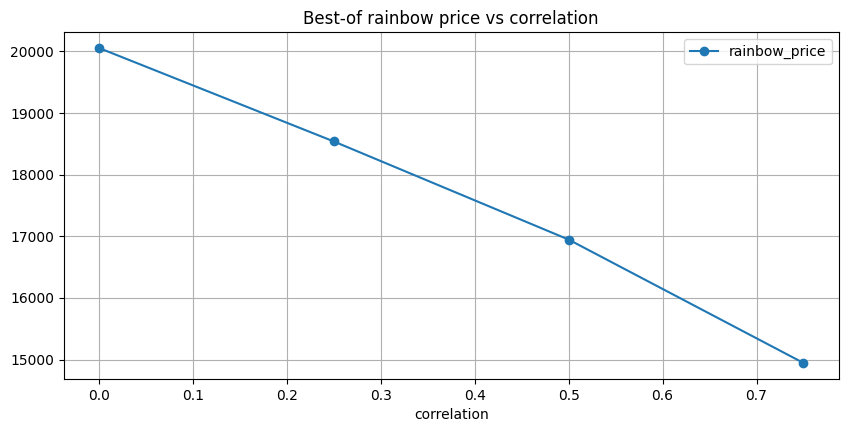

In [6]:
sensitivity=[]
for cc in [.0,.25,.5,.75]:
    x=rainbow_mc(spots,vols,cc,.02,1.,z=z,reference=spots)
    sensitivity.append({'correlation':cc,'rainbow_price':x['price'],'stderr':x['stderr']})
sens=pd.DataFrame(sensitivity)
display(sens.round(2))
sens.plot(x='correlation',y='rainbow_price',marker='o',title='Best-of rainbow price vs correlation');plt.show()

## Streamlit presentation

Launch `streamlit run app_01_exotic_book.py` from the repository root. The dashboard exposes Monte Carlo path count, correlation, oil barrier, initial book size, shock timing, volatility multiplier, and transaction costs. It includes pricing, P&L, daily Greeks, cross-gamma, delta and oil-vanilla vega-proxy hedge inventory, unwind visualizations and CSV export.

**Interview discussion:** explain why the best-of payoff is correlated, why barrier delta is unstable near a knock-out boundary, how notional normalization changes Greeks, and how a volatility spike affects both exotic marks and the practical feasibility of an unwind.